<a href="https://colab.research.google.com/github/saratyulyuova/tenge-ruble-network/blob/main/network_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tenge and Ruble in the Emerging-Market Currency Network, 2015–2026

**Author:** Sara Tyulyuova

**Research question:** How did the network position of the Kazakhstani tenge relative to the Russian ruble change after February 2022?

**H₀:** The correlation-based network distance between KZT and RUB is the same before and after 24 February 2022.
**H₁:** The distance changed (two-sided test).

## 1. Setup and data

In [194]:
!pip install -q yfinance networkx


In [195]:
import yfinance as yf          # downloads market data from Yahoo Finance
import pandas as pd            # tables (DataFrames) and time series
import numpy as np             # fast math on arrays
import matplotlib.pyplot as plt  # plots
import networkx as nx          # graphs and minimum spanning trees

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | numpy 2.1.3 | yfinance 0.2.66


In [196]:
tickers = ["KZT=X", "RUB=X"]   # KZT=X means: how many tenge for 1 US dollar

raw = yf.download(tickers, start="2015-08-01", end="2026-10-01", progress=False)
px = raw["Close"]              # keep only daily closing prices
px.columns = ["KZT", "RUB"]    # short readable names

px.head()


/tmp/ipykernel_2972/59499654.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(tickers, start="2015-08-01", end="2026-10-01", progress=False)


,KZT,RUB
Date,,
2015-08-03,185.410004,61.630699
2015-08-04,184.770004,63.500000
2015-08-05,184.899994,63.110001
2015-08-06,184.240005,63.382999
2015-08-07,184.929993,64.480003


In [197]:
print("Shape:", px.shape)                       # (rows, columns)
print("From", px.index.min().date(), "to", px.index.max().date())
print("\nMissing values:\n", px.isna().sum())
print("\nSummary:\n", px.describe().round(2))
print("\nLast 5 rows:\n", px.tail())

Shape: (2905, 2)
From 2015-08-03 to 2026-09-30

Missing values:
 KZT    0
RUB    0
dtype: int64

Summary:
            KZT      RUB
count  2905.00  2905.00
mean    410.76    73.09
std      67.69    12.26
min     184.24     0.72
25%     344.85    63.76
50%     423.62    72.48
75%     460.86    79.85
max     546.96   138.97

Last 5 rows:
                    KZT        RUB
Date                             
2026-09-24  429.468536  84.772919
2026-09-25  426.548492  84.998657
2026-09-28  427.972076  81.902596
2026-09-29  424.581116  84.494904
2026-09-30  423.849579  83.745300


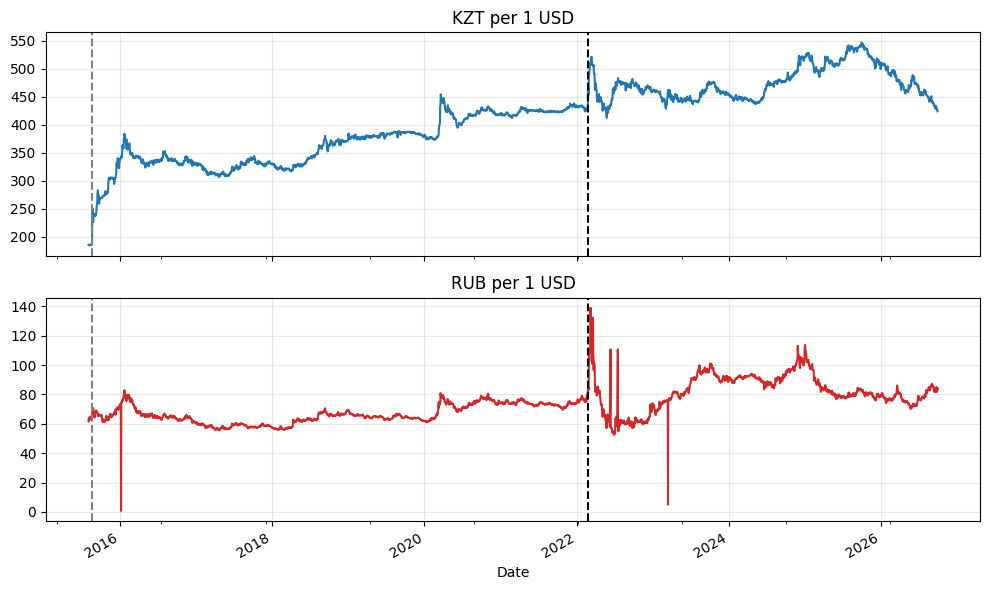

In [198]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

px["KZT"].plot(ax=axes[0], color="tab:blue", title="KZT per 1 USD")
px["RUB"].plot(ax=axes[1], color="tab:red", title="RUB per 1 USD")

for ax in axes:
    ax.axvline(pd.Timestamp("2015-08-20"), ls="--", color="gray")   # tenge free float
    ax.axvline(pd.Timestamp("2022-02-24"), ls="--", color="black")  # start of "post" period
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [199]:
from google.colab import drive
drive.mount("/content/drive")

import os
folder = "/content/drive/MyDrive/tenge-ruble-network/data"
os.makedirs(folder, exist_ok=True)
px.to_csv(f"{folder}/kzt_rub_test.csv")
print("Saved to", folder)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved to /content/drive/MyDrive/tenge-ruble-network/data


In [200]:
# name -> Yahoo Finance ticker
currencies = {
    # main subjects
    "KZT": "KZT=X", "RUB": "RUB=X",
    # commodity exporters
    "NOK": "NOK=X", "CAD": "CAD=X", "AUD": "AUDUSD=X", "BRL": "BRL=X",
    "ZAR": "ZAR=X", "CLP": "CLP=X", "COP": "COP=X", "MXN": "MXN=X",
    # Asia
    "CNY": "CNY=X", "INR": "INR=X", "IDR": "IDR=X", "KRW": "KRW=X",
    "THB": "THB=X", "MYR": "MYR=X", "PHP": "PHP=X",
    # Europe and other emerging markets
    "EUR": "EURUSD=X", "PLN": "PLN=X", "HUF": "HUF=X", "CZK": "CZK=X", "TRY": "TRY=X",
    # safe havens
    "JPY": "JPY=X", "CHF": "CHF=X",
    # optional: Central Asian neighbours (kept only if data are clean)
    "UZS": "UZS=X", "KGS": "KGS=X",
}
invert = ["EUR", "AUD"]   # quoted as USD per 1 unit -> must be flipped

factors = {"GOLD": "GC=F", "OIL": "BZ=F", "DXY": "DX-Y.NYB", "VIX": "^VIX"}

print(len(currencies), "currencies,", len(factors), "other series")

26 currencies, 4 other series


## 1.2 Full sample: ~25 currencies, gold and external factors

Currencies are quoted as units per 1 USD. EUR and AUD are quoted the other way (USD per unit), so they are inverted.
External factors: Brent oil, US dollar index (DXY) and the VIX volatility index.

In [201]:
all_tickers = list(currencies.values()) + list(factors.values())
raw = yf.download(all_tickers, start="2015-08-01", end="2026-10-01", progress=False)["Close"]

# rename columns from tickers to our short names
ticker_to_name = {t: n for n, t in {**currencies, **factors}.items()}
raw = raw.rename(columns=ticker_to_name)

# which series failed completely?
failed = [c for c in raw.columns if raw[c].isna().all()]
print("Shape:", raw.shape)
print("Failed downloads:", failed if failed else "none")

/tmp/ipykernel_2972/3631143000.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(all_tickers, start="2015-08-01", end="2026-10-01", progress=False)["Close"]
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['KGS=X']: YFTzMissingError('possibly delisted; no timezone found')


Shape: (2909, 30)
Failed downloads: ['KGS']


In [202]:
prices = raw[list(currencies) + ["GOLD"]].copy()     # currencies + gold
fac = raw[["OIL", "DXY", "VIX"]].copy()               # external factors

for c in invert:
    prices[c] = 1 / prices[c]                         # now EUR, AUD = units per 1 USD

print(prices[["EUR", "AUD"]].tail(3))


Ticker          EUR       AUD
Date                         
2026-09-28  0.87889  1.426717
2026-09-29  0.87930  1.425232
2026-09-30  0.88177  1.430820


In [203]:
period = prices.loc["2015-09-01":]   # our study period

check = pd.DataFrame({
    "first":       period.bfill().iloc[0].round(3),                    # first value
    "last":        period.ffill().iloc[-1].round(3),                   # last value
    "missing_%":   (period.isna().mean() * 100).round(1),              # share of empty days
    "no_change_%": ((period.diff() == 0).mean() * 100).round(1),       # share of days with zero change
    "big_jumps":   (np.log(period).diff().abs() > 0.10).sum(),         # days with >10% move
})
check.sort_values("missing_%", ascending=False)


,first,last,missing_%,no_change_%,big_jumps
Ticker,,,,,
KGS,NaN,NaN,100.0,0.0,0
GOLD,1138.700,4186.700,3.5,0.5,1
CNY,6.366,6.703,0.2,5.2,0
NOK,8.258,9.598,0.1,0.0,4
CAD,1.314,1.419,0.1,0.1,0
BRL,3.619,5.203,0.1,0.3,0
AUD,1.407,1.431,0.1,0.1,0
ZAR,13.266,16.391,0.1,0.0,6
CLP,692.200,973.000,0.1,1.2,3


In [204]:
jumps = np.log(period).diff().abs()
for c in check.index[check["big_jumps"] > 0]:
    print(c, list(jumps.index[jumps[c] > 0.10].date))

RUB [datetime.date(2016, 1, 6), datetime.date(2016, 1, 7), datetime.date(2022, 3, 1), datetime.date(2022, 3, 8), datetime.date(2022, 3, 16), datetime.date(2022, 3, 21), datetime.date(2022, 3, 22), datetime.date(2022, 3, 30), datetime.date(2022, 6, 13), datetime.date(2022, 6, 14), datetime.date(2022, 7, 6), datetime.date(2022, 7, 18), datetime.date(2022, 7, 19), datetime.date(2023, 3, 16), datetime.date(2023, 3, 17)]
NOK [datetime.date(2020, 3, 20), datetime.date(2020, 3, 23), datetime.date(2021, 1, 1), datetime.date(2021, 1, 4)]
ZAR [datetime.date(2024, 11, 15), datetime.date(2024, 11, 18), datetime.date(2025, 1, 15), datetime.date(2025, 1, 16), datetime.date(2025, 1, 17), datetime.date(2025, 1, 20)]
CLP [datetime.date(2016, 12, 22), datetime.date(2016, 12, 23), datetime.date(2022, 7, 21)]
COP [datetime.date(2015, 12, 10), datetime.date(2015, 12, 11), datetime.date(2015, 12, 15), datetime.date(2015, 12, 16), datetime.date(2016, 2, 18), datetime.date(2016, 2, 19)]
PHP [datetime.date(201

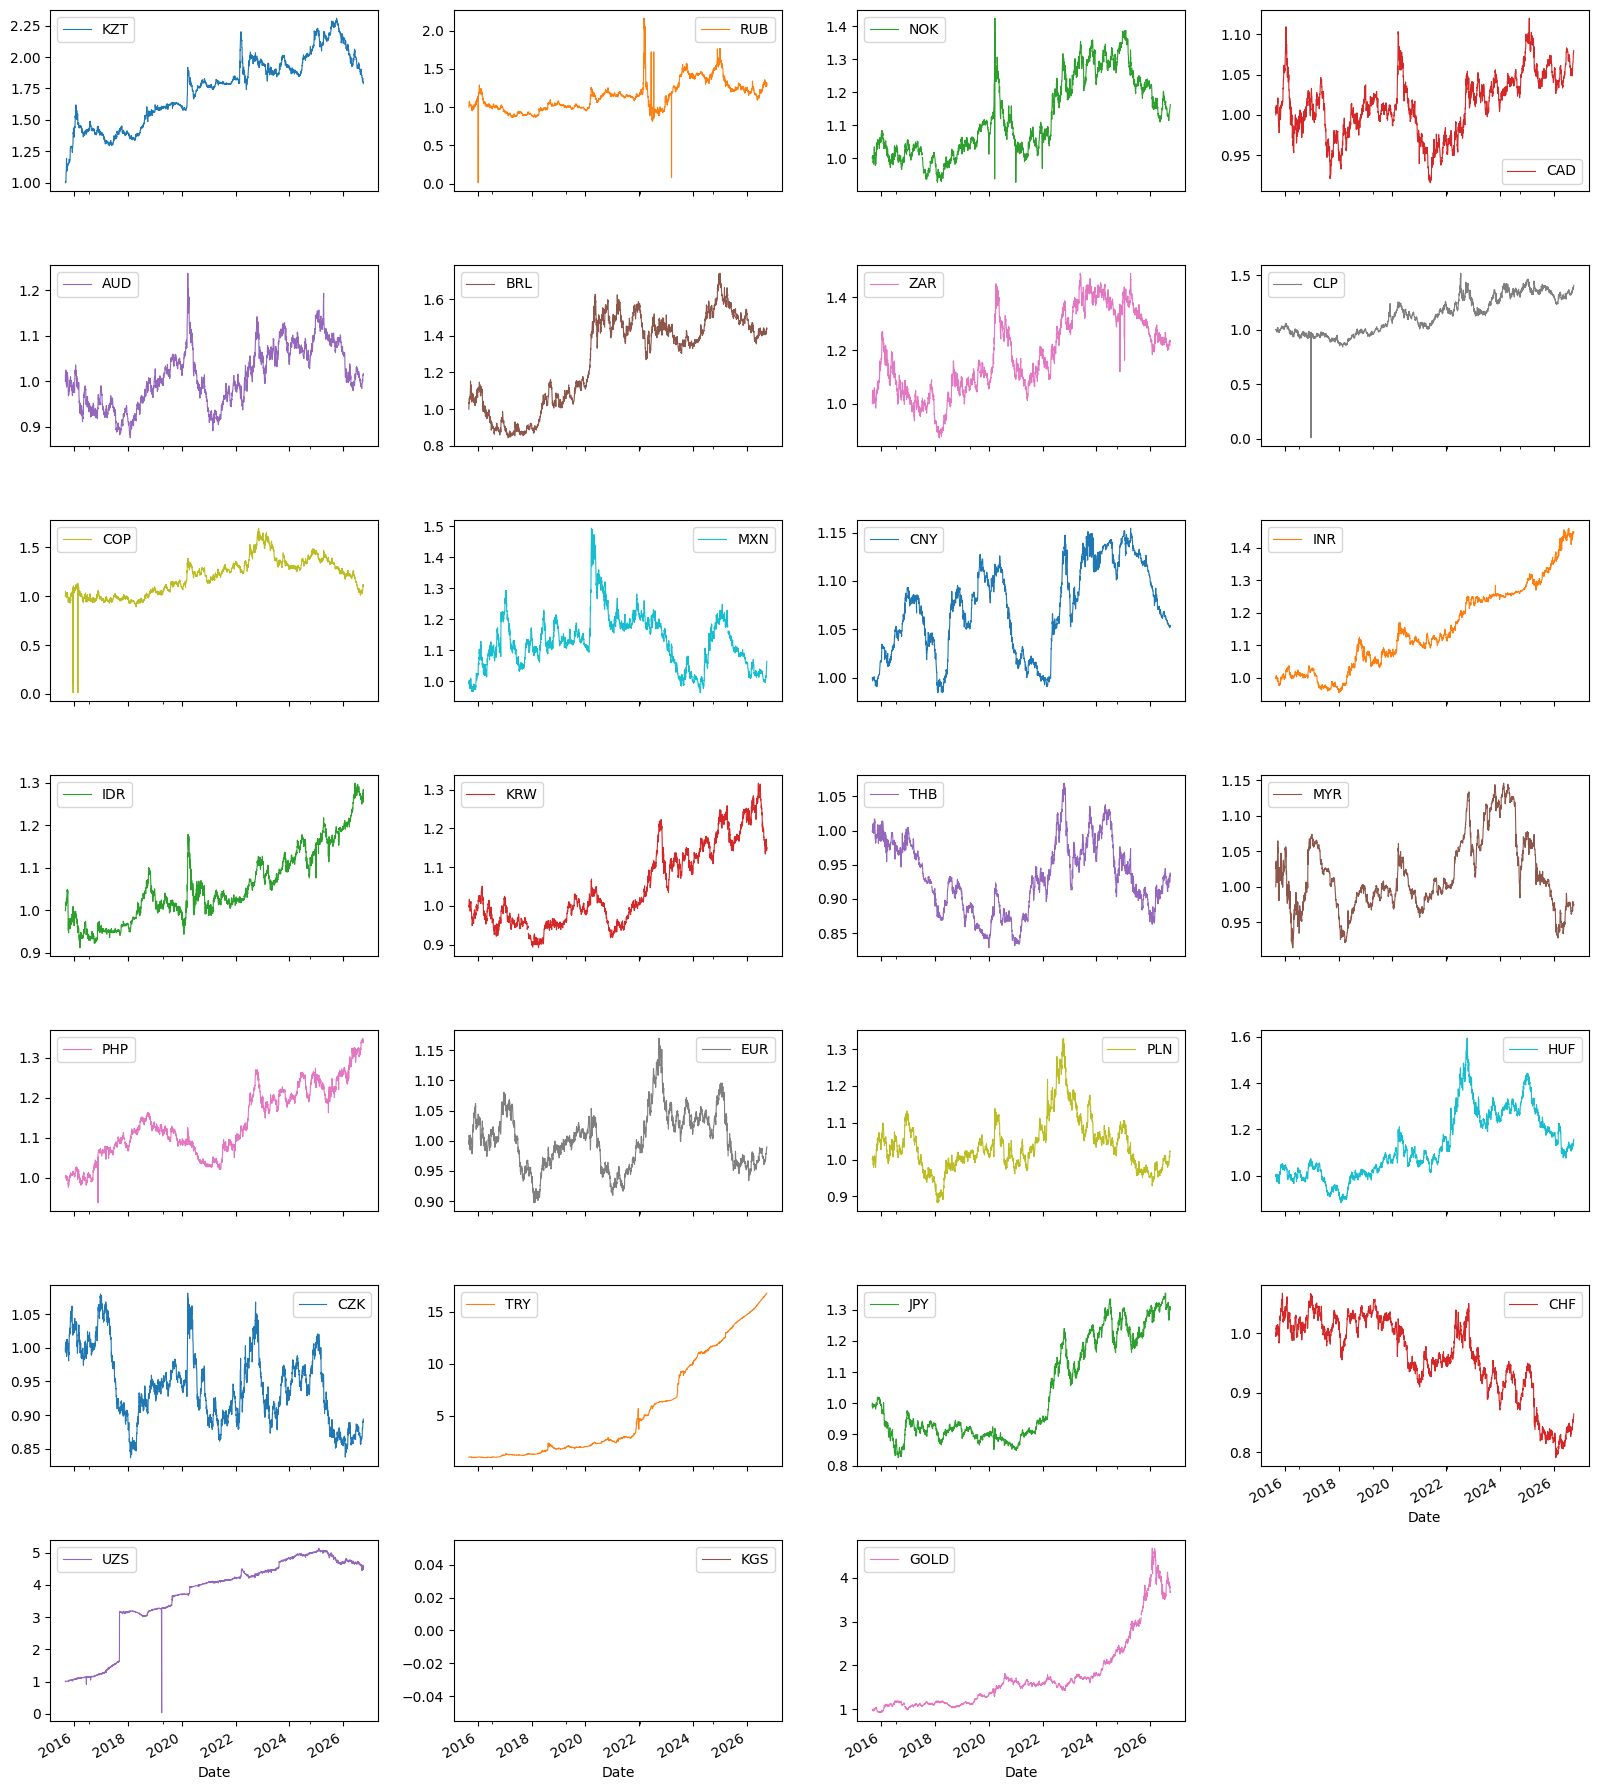

In [205]:
(period / period.bfill().iloc[0]).plot(subplots=True, layout=(7, 4), figsize=(16, 18),
                                       sharex=True, legend=True, lw=0.8)
plt.tight_layout(); plt.show()

**Exclusion rule.** A currency is excluded if (a) more than 5% of days are missing,
or (b) the rate does not change on more than 20% of days (a peg or stale data).
Jumps above 10% are checked against known events; data errors are reported.

Ticker
OIL    3.5
DXY    3.5
VIX    3.5
dtype: float64


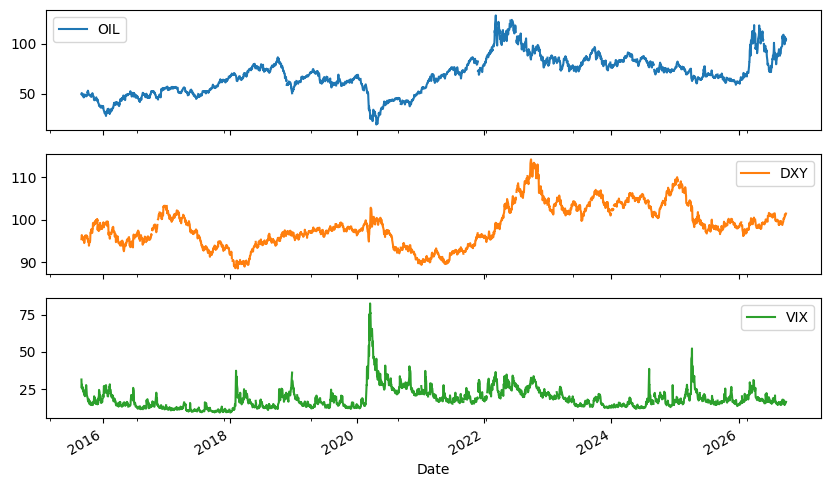

In [206]:
fac_period = fac.loc["2015-09-01":]
print((fac_period.isna().mean() * 100).round(1))
fac_period.plot(subplots=True, figsize=(10, 6), sharex=True); plt.show()

In [207]:
from google.colab import drive
drive.mount("/content/drive")
folder = "/content/drive/MyDrive/tenge-ruble-network/data"
os.makedirs(folder, exist_ok=True)

prices_clean.to_csv(f"{folder}/raw_prices.csv")
fac.to_csv(f"{folder}/factors.csv")
print("Saved:", os.listdir(folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: ['kzt_rub_test.csv', 'raw_prices.csv', 'factors.csv']


In [208]:
# Step 4: split into currencies and factors, flip EUR and AUD
prices = raw[list(currencies) + ["GOLD"]].copy()
fac = raw[["OIL", "DXY", "VIX"]].copy()
for c in ["EUR", "AUD"]:
    prices[c] = 1 / prices[c]

# Step 6 (for now): no extra exclusions yet, KGS is already removed
excluded = {}
prices_clean = prices.drop(columns=list(excluded))

print("prices_clean:", prices_clean.shape, "| fac:", fac.shape)
print(prices_clean[["EUR", "AUD"]].tail(2))

prices_clean: (2909, 27) | fac: (2909, 3)
Ticker          EUR       AUD
Date                         
2026-09-29  0.87930  1.425232
2026-09-30  0.88177  1.430820


In [209]:
period = prices.loc["2015-09-01":]

check = pd.DataFrame({
    "first":       period.bfill().iloc[0].round(3),
    "last":        period.ffill().iloc[-1].round(3),
    "missing_%":   (period.isna().mean() * 100).round(1),
    "no_change_%": ((period.diff() == 0).mean() * 100).round(1),
    "big_jumps":   (np.log(period).diff().abs() > 0.10).sum(),
})
check.sort_values("missing_%", ascending=False)

,first,last,missing_%,no_change_%,big_jumps
Ticker,,,,,
KGS,NaN,NaN,100.0,0.0,0
GOLD,1138.700,4186.700,3.5,0.5,1
CNY,6.366,6.703,0.2,5.2,0
NOK,8.258,9.598,0.1,0.0,4
CAD,1.314,1.419,0.1,0.1,0
BRL,3.619,5.203,0.1,0.3,0
AUD,1.407,1.431,0.1,0.1,0
ZAR,13.266,16.391,0.1,0.0,6
CLP,692.200,973.000,0.1,1.2,3


In [210]:
jumps = np.log(period).diff().abs()
for c in ["RUB", "NOK", "ZAR", "COP", "TRY", "CLP", "PHP", "UZS", "KZT"]:
    dates = list(jumps.index[jumps[c] > 0.10].date)
    print(c, dates)

RUB [datetime.date(2016, 1, 6), datetime.date(2016, 1, 7), datetime.date(2022, 3, 1), datetime.date(2022, 3, 8), datetime.date(2022, 3, 16), datetime.date(2022, 3, 21), datetime.date(2022, 3, 22), datetime.date(2022, 3, 30), datetime.date(2022, 6, 13), datetime.date(2022, 6, 14), datetime.date(2022, 7, 6), datetime.date(2022, 7, 18), datetime.date(2022, 7, 19), datetime.date(2023, 3, 16), datetime.date(2023, 3, 17)]
NOK [datetime.date(2020, 3, 20), datetime.date(2020, 3, 23), datetime.date(2021, 1, 1), datetime.date(2021, 1, 4)]
ZAR [datetime.date(2024, 11, 15), datetime.date(2024, 11, 18), datetime.date(2025, 1, 15), datetime.date(2025, 1, 16), datetime.date(2025, 1, 17), datetime.date(2025, 1, 20)]
COP [datetime.date(2015, 12, 10), datetime.date(2015, 12, 11), datetime.date(2015, 12, 15), datetime.date(2015, 12, 16), datetime.date(2016, 2, 18), datetime.date(2016, 2, 19)]
TRY [datetime.date(2018, 8, 13), datetime.date(2021, 3, 22), datetime.date(2021, 11, 24), datetime.date(2021, 12,

In [211]:
def clean_spikes(p, thr=0.10):
    """Remove one-day spikes that immediately reverse (data errors)."""
    p = p.copy()
    r = np.log(p).diff()
    log = []
    for c in p.columns:
        now, nxt = r[c], r[c].shift(-1)
        spike = ((now.abs() > thr) & (nxt.abs() > thr)           # big move today AND tomorrow
                 & (np.sign(now) != np.sign(nxt))                 # in opposite directions
                 & ((now + nxt).abs() < 0.3 * now.abs()))         # tomorrow almost undoes today
        for d in p.index[spike]:
            log.append((c, d.date()))
        p.loc[spike, c] = np.nan
    return p.ffill(limit=1), log

prices_fixed, removed = clean_spikes(prices_clean)
print("Removed", len(removed), "spike days:")
for c, d in removed:
    print(" ", c, d)

Removed 17 spike days:
  RUB 2016-01-06
  RUB 2022-03-21
  RUB 2022-06-13
  RUB 2022-07-18
  RUB 2023-03-16
  NOK 2020-03-20
  NOK 2021-01-01
  ZAR 2024-11-15
  ZAR 2025-01-15
  ZAR 2025-01-17
  CLP 2016-12-22
  COP 2015-12-10
  COP 2015-12-15
  COP 2016-02-18
  PHP 2016-11-17
  UZS 2016-06-13
  UZS 2019-04-01


In [212]:
period2 = prices_fixed.loc["2015-09-01":]
jumps2 = np.log(period2).diff().abs()
for c in period2.columns:
    dates = list(jumps2.index[jumps2[c] > 0.10].date)
    if dates:
        print(c, dates)

RUB [datetime.date(2022, 3, 1), datetime.date(2022, 3, 8), datetime.date(2022, 3, 16), datetime.date(2022, 3, 30), datetime.date(2022, 7, 6)]
CLP [datetime.date(2022, 7, 21)]
TRY [datetime.date(2018, 8, 13), datetime.date(2021, 3, 22), datetime.date(2021, 11, 24), datetime.date(2021, 12, 21)]
UZS [datetime.date(2017, 9, 5)]
GOLD [datetime.date(2026, 1, 30)]


In [213]:
excluded = {
    "KGS": "no data on Yahoo Finance (ticker not found)",
    "UZS": "rate not market-determined before Sept 2017 liberalisation",
}
prices_fixed = prices_fixed.drop(columns=[c for c in excluded if c in prices_fixed.columns])
prices_fixed.to_csv(f"{folder}/raw_prices.csv")
fac.to_csv(f"{folder}/factors.csv")
print("Saved:", prices_fixed.shape[1], "series:", list(prices_fixed.columns))

Saved: 25 series: ['KZT', 'RUB', 'NOK', 'CAD', 'AUD', 'BRL', 'ZAR', 'CLP', 'COP', 'MXN', 'CNY', 'INR', 'IDR', 'KRW', 'THB', 'MYR', 'PHP', 'EUR', 'PLN', 'HUF', 'CZK', 'TRY', 'JPY', 'CHF', 'GOLD']


In [214]:
prices_fixed.to_csv(f"{folder}/raw_prices.csv")
print("Saved clean prices:", prices_fixed.shape)

Saved clean prices: (2909, 25)
